First 5 rows of data:
   eye_contact  met_again  story_replies  chat_days  common_interests  love
0            0          0              0         43                 9     0
1            1          0              1         53                 8     1
2            0          0              1         38                 8     1
3            0          1              1         26                 5     1
4            0          1              0          9                 7     0 

Love (1) vs No love (0):
love
1    191
0    109
Name: count, dtype: int64 



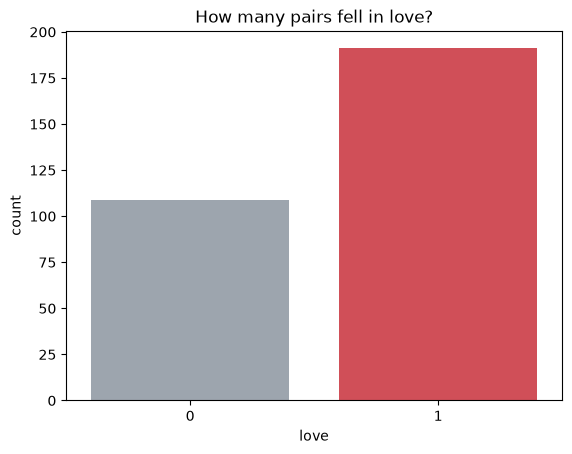

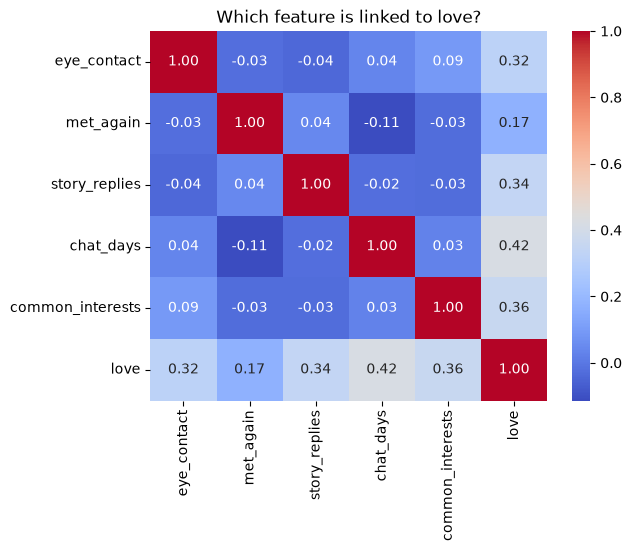

Train rows: 240 | Test rows: 60 

Decision Tree: accuracy = 76.67%
KNN (k=5): accuracy = 81.67%
Naive Bayes: accuracy = 88.33%


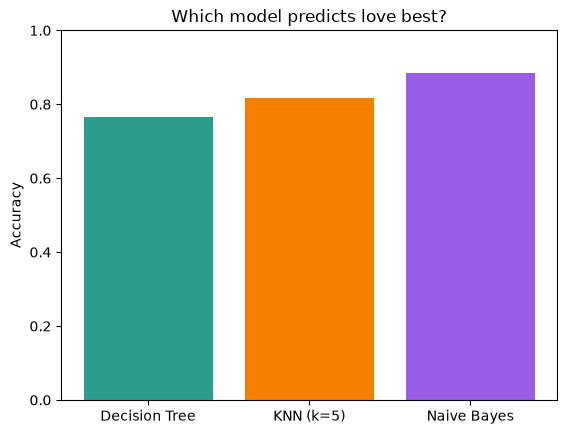

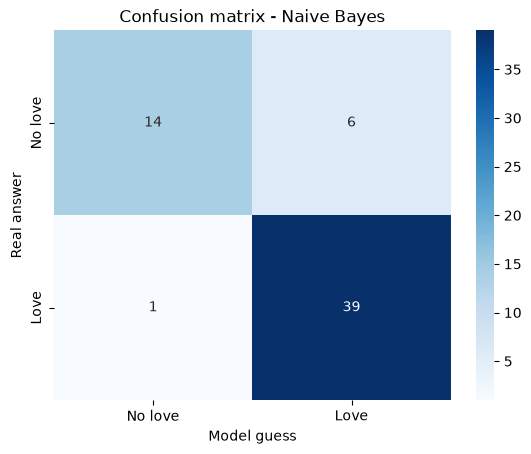

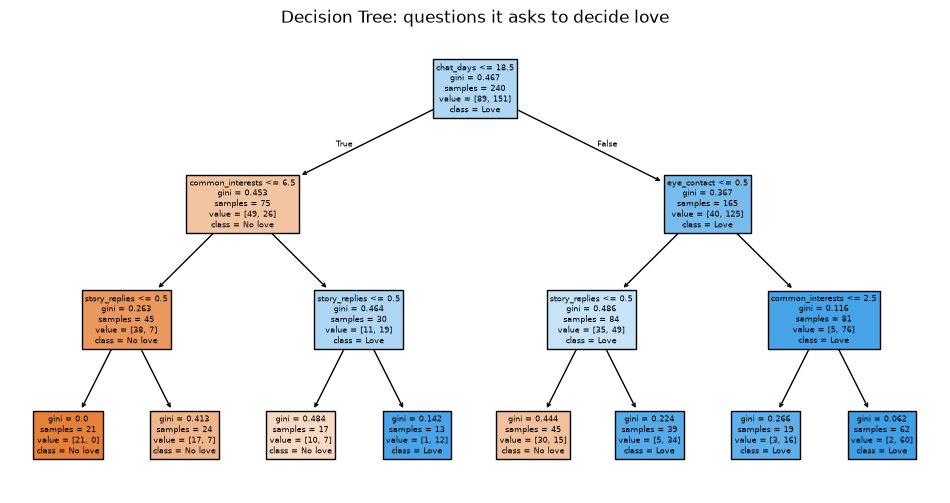


Prediction for Arjun and Meera:
  Decision Tree: They fall in love!
  KNN (k=5): They fall in love!
  Naive Bayes: They fall in love!


In [1]:
"""
Love Story Machine Learning (beginner level)
Question: will Arjun and Meera fall in love?
We teach 3 models (Decision Tree, KNN, Naive Bayes) with practice data.

Install once:  pip install pandas numpy matplotlib seaborn scikit-learn
Run:           python love_story_ml.py
"""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix

# ---------- STEP 1: make practice data (numpy + pandas) ----------
np.random.seed(42)
n = 300  # 300 imaginary pairs of boy and girl

data = pd.DataFrame({
    "eye_contact":      np.random.randint(0, 2, n),    # 1 = looked at each other
    "met_again":        np.random.randint(0, 2, n),    # 1 = met at another function
    "story_replies":    np.random.randint(0, 2, n),    # 1 = replied to Instagram story
    "chat_days":        np.random.randint(0, 60, n),   # days they chatted
    "common_interests": np.random.randint(0, 11, n),   # 0 to 10
})

# Our simple "love rule" plus some random luck, so data is not perfect
score = (data["eye_contact"] * 2 + data["met_again"] * 2 + data["story_replies"] * 3
         + data["chat_days"] / 10 + data["common_interests"] / 2
         + np.random.normal(0, 1.5, n))
data["love"] = (score > 8).astype(int)   # 1 = fell in love, 0 = did not

print("First 5 rows of data:")
print(data.head(), "\n")
print("Love (1) vs No love (0):")
print(data["love"].value_counts(), "\n")

# ---------- STEP 2: look at the data (seaborn) ----------
sns.countplot(x="love", hue="love", data=data, palette=["#9aa5b1", "#e63946"], legend=False)
plt.title("How many pairs fell in love?")
plt.savefig("ml_1_love_count.png", dpi=110, bbox_inches="tight")
plt.show()

sns.heatmap(data.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Which feature is linked to love?")
plt.savefig("ml_2_correlation.png", dpi=110, bbox_inches="tight")
plt.show()

# ---------- STEP 3: split into train and test ----------
X = data.drop("love", axis=1)    # inputs (features)
y = data["love"]                 # answer (label)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)
print("Train rows:", len(X_train), "| Test rows:", len(X_test), "\n")

# ---------- STEP 4: train 3 models ----------
models = {
    "Decision Tree": DecisionTreeClassifier(max_depth=3, random_state=42),
    "KNN (k=5)": KNeighborsClassifier(n_neighbors=5),
    "Naive Bayes": GaussianNB(),
}
results = {}
for name, model in models.items():
    model.fit(X_train, y_train)                 # learn
    pred = model.predict(X_test)                # guess
    results[name] = accuracy_score(y_test, pred)
    print(f"{name}: accuracy = {results[name]:.2%}")

# ---------- STEP 5: compare the models ----------
plt.bar(results.keys(), results.values(), color=["#2a9d8f", "#f77f00", "#9b5de5"])
plt.ylim(0, 1)
plt.ylabel("Accuracy")
plt.title("Which model predicts love best?")
plt.savefig("ml_3_model_compare.png", dpi=110, bbox_inches="tight")
plt.show()

# ---------- STEP 6: confusion matrix of the best model ----------
best_name = max(results, key=results.get)
best = models[best_name]
cm = confusion_matrix(y_test, best.predict(X_test))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No love", "Love"], yticklabels=["No love", "Love"])
plt.xlabel("Model guess"); plt.ylabel("Real answer")
plt.title(f"Confusion matrix - {best_name}")
plt.savefig("ml_4_confusion.png", dpi=110, bbox_inches="tight")
plt.show()

# ---------- STEP 7: see how the Decision Tree thinks ----------
plt.figure(figsize=(12, 6))
plot_tree(models["Decision Tree"], feature_names=X.columns,
          class_names=["No love", "Love"], filled=True)
plt.title("Decision Tree: questions it asks to decide love")
plt.savefig("ml_5_tree.png", dpi=110, bbox_inches="tight")
plt.show()

# ---------- STEP 8: predict OUR story ----------
arjun_meera = pd.DataFrame([{
    "eye_contact": 1,        # they looked at each other in the car
    "met_again": 1,          # New Year function
    "story_replies": 1,      # Instagram story chat
    "chat_days": 30,
    "common_interests": 7,
}])
print("\nPrediction for Arjun and Meera:")
for name, model in models.items():
    answer = model.predict(arjun_meera)[0]
    print(f"  {name}: {'They fall in love!' if answer == 1 else 'Just friends'}")